# Experiment 17: Learning-rate schedule

Card: [exp17_lr_schedule.md](../../experiments/exp17_lr_schedule.md)


In [ ]:
import os
import sys
from time import perf_counter

import lightning.pytorch as L
from lightning.pytorch.callbacks import EarlyStopping
import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
import torch

sys.path.insert(0, "../../..")  # the ashrae package lives in the homework folder
from ashrae.config import FOLDS
from ashrae.data import read_processed, split
from ashrae.features import build_features
from ashrae.metrics import rmsle
from ashrae.modeling import MeterMLP, make_loaders, predict
from ashrae.tracking import Experiment

SMOKE = os.environ.get("SMOKE") == "1"
NOTEBOOK = "exp17_lr_schedule"
EMB_DIM = 12  # picked in exp03
LR = 1e-2  # starting learning rate of every schedule
WIDTH, DROPOUT, N_LAYERS = 64, 0.1, 2  # picked in exp15 and exp16
SCHEDULES = ["cosine", "step", "plateau"]
PATIENCE = 3  # plateau: epochs without a lower validation RMSLE before halving
if SMOKE:
    EXPERIMENT = "ashrae-mlp-lr-schedule-smoke"
    TRAIN = True
    SESSION = None
    FOLD_NAMES = list(FOLDS)[:1]
    N_TRAIN, N_VAL = 20_000, 5_000
    EPOCHS = 3
    # (experiment, session, dropout) of the reused constant-lr runs; None: the latest session
    REFERENCE = (
        "ashrae-mlp-small-width-dropout-smoke",
        None,
        0.3,
    )  # stands in for dropout 0.1
    FIGURE = None
else:
    EXPERIMENT = "ashrae-mlp-lr-schedule"
    TRAIN = (
        True  # set False with SESSION to re-read a finished session without training
    )
    SESSION = None
    FOLD_NAMES = list(FOLDS)
    N_TRAIN, N_VAL = 2_000_000, 500_000
    EPOCHS = 40
    REFERENCE = (
        "ashrae-mlp-small-width-dropout",
        "2026-10-13 09:06:41",
        DROPOUT,
    )  # exp15
    FIGURE = "../../figures/exp17_lr_schedule.png"

experiment = Experiment(EXPERIMENT, NOTEBOOK, SESSION)

/Users/lupaskodmitro/FuckIT/Machine Learning/Deep Learning Homeworks/Homework 1 MLP/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026/10/13 10:29:05 INFO mlflow.tracking.fluent: Experiment with name 'ashrae-mlp-lr-schedule' does not exist. Creating a new experiment.


MLflow: sqlite:////Users/lupaskodmitro/FuckIT/Machine Learning/Deep Learning Homeworks/Homework 1 MLP/mlflow.db, experiment 'ashrae-mlp-lr-schedule', session 2026-10-13 10:29:04


## Training


In [ ]:
def at_best(run_id):
    """A run's scores at its best validation epoch and its per-epoch curves; a diverged run scores inf."""
    val = np.array(experiment.history(run_id, "val_rmsle"))
    train = np.array(experiment.history(run_id, "train_rmsle"))
    if not np.isfinite(val).all():
        return {"val": np.inf, "val_curve": val, "train_curve": train}
    b = int(val.argmin())
    return {
        "best_epoch": b + 1,
        "val": val[b],
        "val_clean": experiment.history(run_id, "val_rmsle_clean")[b],
        "train": train[b],
        "val_last": val[-1],
        "val_clean_last": experiment.history(run_id, "val_rmsle_clean")[-1],
        "train_last": train[-1],
        "epoch_seconds": np.mean(experiment.history(run_id, "epoch_seconds")),
        "val_curve": val,
        "train_curve": train,
        # the reused constant-lr runs logged no lr
        "lr_curve": np.array(experiment.history(run_id, "lr") or [LR] * len(val)),
    }


def session_runs(name, session):
    """Finished runs of one session of another notebook (the latest one if `session` is None)."""
    runs = mlflow.search_runs(
        experiment_names=[name], filter_string="attributes.status = 'FINISHED'"
    )
    runs = runs.rename(columns=lambda c: c.removeprefix("tags."))
    return runs[runs.session == (session or runs.session.max())]


def scores():
    own = experiment.runs().rename(columns=lambda c: c.removeprefix("tags."))
    own = own[own.status == "FINISHED"]  # an interrupted run is retrained
    name, session, p = REFERENCE
    ref = session_runs(name, session)
    ref = ref[
        (ref["params.lr"].astype(float) == LR)
        & (ref.width.astype(int) == WIDTH)
        & (ref.dropout.astype(float) == p)
    ]
    runs = pd.concat([own, ref.assign(schedule="constant")])[
        ["run_id", "schedule", "fold"]
    ]
    runs = runs[runs.fold.isin(FOLD_NAMES)].reset_index(drop=True)
    scored = pd.DataFrame([at_best(r) for r in runs.run_id], index=runs.index)
    results = pd.concat([runs, scored], axis=1)
    results["minutes_to_best"] = results.epoch_seconds * results.best_epoch / 60
    return results


def optimizer(schedule):
    """Adam at LR with the schedule stepped once per epoch."""

    def make(params):
        opt = torch.optim.Adam(params, lr=LR)
        if schedule == "cosine":
            sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)
        elif schedule == "step":
            sched = torch.optim.lr_scheduler.MultiStepLR(
                opt, milestones=[EPOCHS // 2, EPOCHS * 3 // 4], gamma=0.1
            )
        else:
            sched = torch.optim.lr_scheduler.ReduceLROnPlateau(
                opt, factor=0.5, patience=PATIENCE
            )
        return {
            "optimizer": opt,
            "lr_scheduler": {
                "scheduler": sched,
                "monitor": "val_rmsle",
                "interval": "epoch",
            },
        }

    return make


class CleanRMSLE(L.Callback):
    """Logs validation RMSLE on the clean rows after every epoch, so it can be read at the best epoch."""

    def __init__(self, loader, y):
        self.loader, self.y = loader, y

    def on_validation_epoch_end(self, trainer, model):
        if not trainer.sanity_checking:
            model.log("val_rmsle_clean", rmsle(self.y, predict(model, self.loader)))


class EpochSeconds(L.Callback):
    """Logs the wall time of each epoch's training batches, without validation."""

    def on_train_epoch_start(self, trainer, model):
        self.start = perf_counter()

    def on_validation_start(self, trainer, model):
        if not trainer.sanity_checking:
            self.seconds = perf_counter() - self.start

    def on_validation_epoch_end(self, trainer, model):
        if not trainer.sanity_checking:
            model.log("epoch_seconds", self.seconds)


class EpochLR(L.Callback):
    """Logs the learning rate each epoch trained with."""

    def on_train_epoch_start(self, trainer, model):
        # read here: the scheduler has already stepped by validation end
        self.lr = trainer.optimizers[0].param_groups[0]["lr"]

    def on_validation_epoch_end(self, trainer, model):
        if not trainer.sanity_checking:
            model.log("lr", self.lr)

In [3]:
if TRAIN:
    df = read_processed()
    n_buildings = int(df.building_id.max()) + 1
    folds = {}
    for fold in FOLD_NAMES:
        train_df, val_df = split(df, FOLDS[fold], N_TRAIN, N_VAL)
        year_median = train_df.year_built.median()
        X_train, X_val = build_features(train_df, year_median), build_features(
            val_df, year_median
        )
        clean = ~val_df.anomaly.to_numpy()
        folds[fold] = {
            "loaders": make_loaders(train_df, val_df, X_train, X_val)[:2],
            "clean": (
                make_loaders(train_df, val_df[clean], X_train, X_val[clean])[1],
                np.log1p(val_df.meter_reading.to_numpy(dtype="float32")[clean]),
            ),
        }
    del df
    n_features = X_train.shape[1]
    done = (
        set()
        if SESSION is None
        else set(
            scores()
            .query("schedule != 'constant'")[["schedule", "fold"]]
            .itertuples(index=False, name=None)
        )
    )

    for schedule in SCHEDULES:
        for fold, d in folds.items():
            if (schedule, fold) in done:
                continue
            experiment.fit(
                lambda: MeterMLP(
                    n_features,
                    n_buildings,
                    emb_dim=EMB_DIM,
                    batch_norm=True,
                    dropout=DROPOUT,
                    width=WIDTH,
                    n_layers=N_LAYERS,
                ),
                *d["loaders"],
                run_name=f"mlp_4out_emb_bn | {schedule} | {fold}",
                epochs=EPOCHS,
                lr=LR,
                optimizer=optimizer(schedule),
                callbacks=[
                    CleanRMSLE(*d["clean"]),
                    EpochSeconds(),
                    EpochLR(),
                    # stops a diverged run only: patience never runs out
                    EarlyStopping("val_rmsle", patience=EPOCHS, check_finite=True),
                ],
                tags={
                    "fold": fold,
                    "model": "mlp_4out_emb_bn",
                    "schedule": schedule,
                    "layers": str(N_LAYERS),
                    "width": str(WIDTH),
                    "dropout": f"{DROPOUT:g}",
                },
                params={
                    "n_train": N_TRAIN,
                    "n_val": N_VAL,
                    "emb_dim": EMB_DIM,
                    "width": WIDTH,
                    "dropout": DROPOUT,
                    "n_layers": N_LAYERS,
                    "schedule": schedule,
                },
            )

mlp_4out_emb_bn | cosine | Jan–Mar: 100%|██████████| 19560/19560 [01:23<00:00, 235.32batch/s, epoch 40, val 1.3920, best 1.3877 at 26]
mlp_4out_emb_bn | cosine | Apr–Jun: 100%|██████████| 19560/19560 [01:22<00:00, 237.21batch/s, epoch 40, val 1.1952, best 1.1884 at 24]
mlp_4out_emb_bn | cosine | Jul–Sep: 100%|██████████| 19560/19560 [01:22<00:00, 236.36batch/s, epoch 40, val 1.0097, best 1.0060 at 31]
mlp_4out_emb_bn | cosine | Oct–Dec: 100%|██████████| 19560/19560 [01:21<00:00, 239.59batch/s, epoch 40, val 1.0861, best 1.0845 at 27]
mlp_4out_emb_bn | step | Jan–Mar: 100%|██████████| 19560/19560 [01:21<00:00, 239.16batch/s, epoch 40, val 1.3919, best 1.3870 at 17]
mlp_4out_emb_bn | step | Apr–Jun: 100%|██████████| 19560/19560 [01:22<00:00, 235.83batch/s, epoch 40, val 1.1940, best 1.1914 at 24]
mlp_4out_emb_bn | step | Jul–Sep: 100%|██████████| 19560/19560 [01:21<00:00, 239.27batch/s, epoch 40, val 1.0069, best 1.0049 at 27]
mlp_4out_emb_bn | step | Oct–Dec: 100%|██████████| 19560/1956

## Results


In [5]:
results = scores()
print(f"MLflow session {experiment.session}: {len(results)} runs, with the reused ones")

columns = {
    "val_clean": "average, clean rows",
    "val_last": f"average at epoch {EPOCHS}",
    "val_clean_last": f"average at epoch {EPOCHS}, clean rows",
    "best_epoch": "best epoch",
    "train": "training at best epoch",
    "train_last": f"training at epoch {EPOCHS}",
    "epoch_seconds": "seconds per epoch",
    "minutes_to_best": "minutes to best epoch",
}
by_setup = results.groupby("schedule")[["val", *columns]].mean()
table = results.pivot_table(index="schedule", columns="fold", values="val")[FOLD_NAMES]
table["average"] = by_setup.val
table = table.join(by_setup[list(columns)].rename(columns=columns))
display(
    table.round(3).rename_axis(columns="RMSLE at the best epoch, all rows unless noted")
)

best = by_setup.val.idxmin()
print("best schedule:", best)

MLflow session 2026-10-13 10:29:04: 16 runs, with the reused ones


"RMSLE at the best epoch, all rows unless noted",Jan–Mar,Apr–Jun,Jul–Sep,Oct–Dec,average,"average, clean rows",average at epoch 40,"average at epoch 40, clean rows",best epoch,training at best epoch,training at epoch 40,seconds per epoch,minutes to best epoch
schedule,,,,,,,,,,,,,
constant,1.379,1.188,1.001,1.081,1.162,0.907,1.165,0.912,27.75,0.815,0.807,1.926,0.890
cosine,1.388,1.188,1.006,1.084,1.167,0.906,1.171,0.908,27.00,0.810,0.802,1.879,0.845
plateau,1.387,1.188,1.006,1.081,1.166,0.906,1.168,0.907,29.25,0.808,0.803,1.924,0.930
step,1.387,1.191,1.005,1.083,1.167,0.907,1.170,0.907,23.25,0.811,0.803,1.869,0.724


best schedule: constant


In [ ]:
INK, TEXT, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
COLORS = {
    "cosine": "#2a78d6",
    "step": "#e07b29",
    "plateau": "#2e9e5b",
}  # blue, orange, green

CURVES = [
    ("val_curve", "validation RMSLE, all rows"),
    ("train_curve", "training RMSLE"),
    ("lr_curve", "learning rate"),
]


def draw(ax, groups, key, label, title):
    for name, runs, color, ls, alpha, zorder in groups:
        # mean over folds; a diverged run is shorter
        curve = pd.DataFrame(runs[key].tolist()).mean()
        ax.plot(
            np.arange(1, len(curve) + 1),
            curve,
            lw=2,
            color=color,
            ls=ls,
            alpha=alpha,
            zorder=zorder,
            label=name,
        )
    ax.set(xlabel="epoch", ylabel=label)
    ax.set_title(title, loc="left", color=TEXT, fontsize=9)
    ax.set_facecolor(SURFACE)
    ax.grid(axis="y", color=GRID, lw=0.75)
    ax.set_axisbelow(True)
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.spines["bottom"].set_color("#c3c2b7")
    ax.tick_params(colors=MUTED, labelcolor=TEXT, length=0, pad=6)

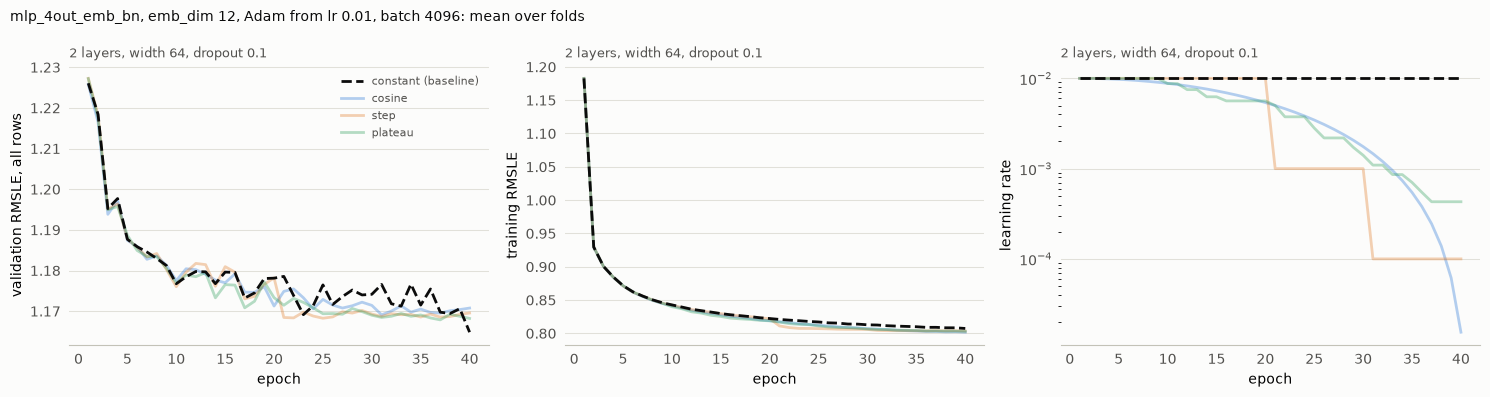

In [ ]:
# The winning schedule in full color, the others faded
alpha = lambda s: 1.0 if s == best else 0.35
groups = [
    (
        "constant (baseline)",
        results.query("schedule == 'constant'"),
        INK,
        "--",
        alpha("constant"),
        3,
    )
] + [
    (s, results.query("schedule == @s"), COLORS[s], "-", alpha(s), 2) for s in SCHEDULES
]
fig, axes = plt.subplots(1, 3, figsize=(15, 4), facecolor=SURFACE)
for ax, (key, label) in zip(axes, CURVES):
    draw(
        ax, groups, key, label, f"{N_LAYERS} layers, width {WIDTH}, dropout {DROPOUT:g}"
    )
axes[2].set_yscale("log")
axes[0].legend(frameon=False, fontsize=8, labelcolor=TEXT)
fig.suptitle(
    f"mlp_4out_emb_bn, emb_dim {EMB_DIM}, Adam from lr {LR:g}, batch 4096: mean over folds",
    x=0.01,
    ha="left",
    color=INK,
    fontsize=10,
)
fig.tight_layout()
if FIGURE:
    fig.savefig(FIGURE, dpi=150, bbox_inches="tight")
    for run_id in results.query("schedule != 'constant'").run_id:
        experiment.client.log_artifact(run_id, FIGURE)